# ZORKO Sangli: food recommendation system

**Mini Project II (7VSIT345), Walchand College of Engineering, Sangli. Team: Utkarsh Patil, Ganesh Mirgane, Anushka Patil.**

This notebook is the analysis and reference implementation of the website's recommender (design: `docs/RECOMMENDATION.md`).

- The website has **no orders or billing**, so the models learn from a **generated demo feedback dataset**: 400 demo users rating the 65 real Sangli dishes, grouped into visits (dishes eaten together). The format follows the team's `feedback.csv`.
- Three signals are combined:
  1. **content similarity** (category, meal role, flavour tags, price, TF-IDF of the description);
  2. **taste similarity** from ratings (item–item collaborative filtering);
  3. **visit co-occurrence** (association rules).

  A **Bayesian quality score** is added on top.
- Two lists per dish: **"Goes well with"** (COMPLEMENT: other meal roles) and **"You may also like"** (SIMILAR: same meal role).

> **Honesty note.** All ratings and comments here are demonstration data. The metrics show how well each method recovers the patterns built into the generator; they do **not** measure real customer taste. Nothing in this notebook is shown on the website as a rating or review.

In [1]:
import sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

sys.path.insert(0, str(Path.cwd()))
import reco_lib as R

FIG = Path("figures"); FIG.mkdir(exist_ok=True)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.titleweight": "bold", "font.size": 10})
ORANGE, BROWN, GREY, GREEN = "#d1430a", "#a93200", "#9a9a9a", "#006947"

def save(name):
    plt.tight_layout(); plt.savefig(FIG / f"{name}.png", bbox_inches="tight"); plt.show()

menu = R.load_menu()
fb = R.load_feedback()
ref = R.load_feedback(R.DATA / "reference" / "feedback_team_v1.csv")
NAME = dict(zip(menu.item_slug, menu.item_name))
ROLE = dict(zip(menu.item_slug, menu.meal_role))
pd.DataFrame({
    "dishes": [len(menu)], "demo users": [fb.user_id.nunique()], "visits": [fb.visit_id.nunique()],
    "ratings": [len(fb)], "first": [fb.timestamp.min()], "last": [fb.timestamp.max()],
})

,dishes,demo users,visits,ratings,first,last
0,65,400,1384,2392,2026-08-01 11:42:00,2026-10-29 21:32:00


## 1. Data overview

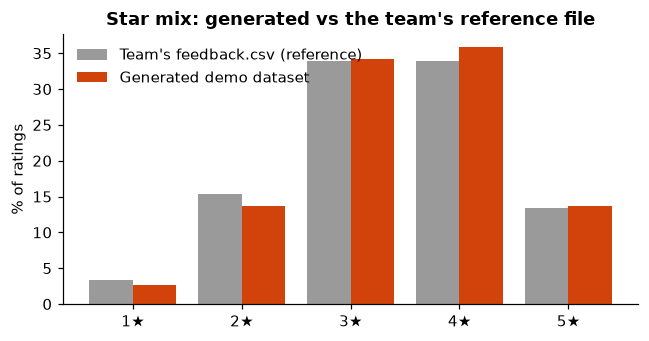

rating,1,2,3,4,5
reference %,3.4,15.4,33.9,33.9,13.4
generated %,2.6,13.7,34.2,35.9,13.7


In [2]:
stars = [1, 2, 3, 4, 5]
ours = fb.rating.value_counts(normalize=True).reindex(stars, fill_value=0) * 100
theirs = ref.rating.value_counts(normalize=True).reindex(stars, fill_value=0) * 100
x = np.arange(5)
plt.figure(figsize=(6, 3.2))
plt.bar(x - 0.2, theirs, 0.4, label="Team's feedback.csv (reference)", color=GREY)
plt.bar(x + 0.2, ours, 0.4, label="Generated demo dataset", color=ORANGE)
plt.xticks(x, [f"{s}★" for s in stars]); plt.ylabel("% of ratings")
plt.title("Star mix: generated vs the team's reference file"); plt.legend(frameon=False)
save("01_star_mix")
pd.DataFrame({"reference %": theirs.round(1), "generated %": ours.round(1)}).T

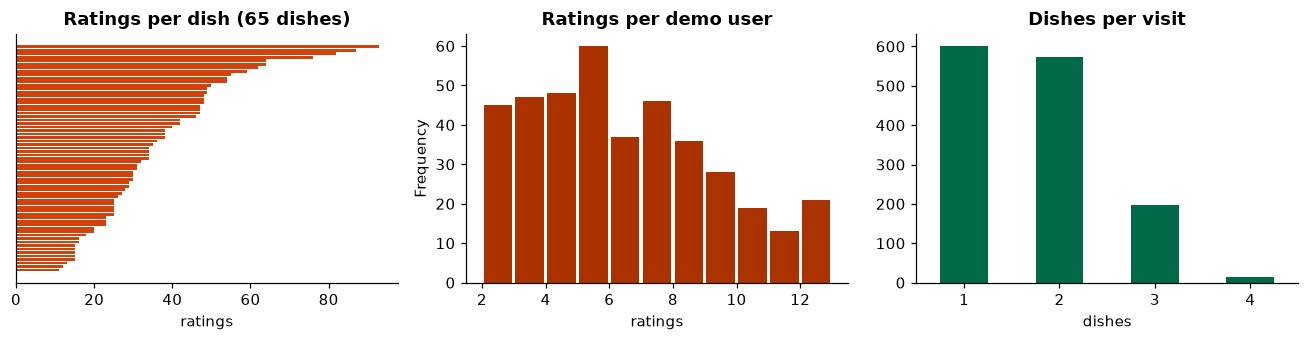

User × dish matrix: 400 × 65, 90.8% empty (sparse).


In [3]:
fig, ax = plt.subplots(1, 3, figsize=(12, 3.2))
per_dish = fb.groupby("item_slug").size().sort_values()
ax[0].barh(range(len(per_dish)), per_dish.values, color=ORANGE)
ax[0].set_yticks([]); ax[0].set_title("Ratings per dish (65 dishes)"); ax[0].set_xlabel("ratings")
fb.groupby("user_id").size().plot.hist(bins=range(2, 14), ax=ax[1], color=BROWN, rwidth=0.9)
ax[1].set_title("Ratings per demo user"); ax[1].set_xlabel("ratings")
fb.groupby("visit_id").size().value_counts().sort_index().plot.bar(ax=ax[2], color=GREEN, rot=0)
ax[2].set_title("Dishes per visit"); ax[2].set_xlabel("dishes")
save("02_distributions")
sparsity = 1 - len(fb) / (fb.user_id.nunique() * len(menu))
print(f"User × dish matrix: {fb.user_id.nunique()} × {len(menu)}, {sparsity:.1%} empty (sparse).")

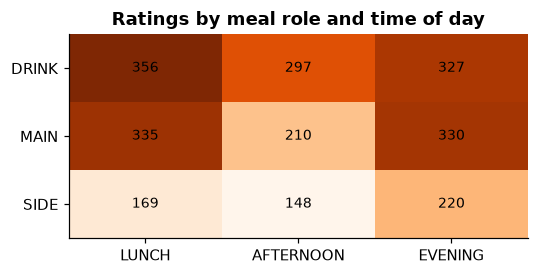

In [4]:
heat = fb.assign(role=fb.item_slug.map(ROLE)).pivot_table(index="role", columns="daypart",
        values="rating", aggfunc="size", fill_value=0)[R.DAYPARTS]
plt.figure(figsize=(5, 2.6))
plt.imshow(heat.values, cmap="Oranges", aspect="auto")
plt.xticks(range(3), heat.columns); plt.yticks(range(len(heat)), heat.index)
for (r, c), v in np.ndenumerate(heat.values):
    plt.text(c, r, v, ha="center", va="center", fontsize=9)
plt.title("Ratings by meal role and time of day"); save("03_daypart_heatmap")

## 2. Content model

Each dish becomes one vector made of weighted blocks, each L2-normalised:

| Block | Weight |
|---|---|
| Category (one-hot) | 1.0 |
| Meal role | 0.5 |
| Flavour tags | 1.5 |
| Price band | 0.5 |
| TF-IDF of name + description | 1.0 |

Similarity is the cosine between these vectors. The TF-IDF settings are fixed (token pattern `[a-z0-9]{2,}`, scikit-learn stop words in `data/reco/stopwords.txt`), so the TypeScript version gives the same numbers.

In [5]:
content = R.content_similarity(R.content_vectors(menu))
slugs = menu.item_slug.tolist()
def most_similar(slug, k=5):
    i = slugs.index(slug)
    order = np.argsort(-content[i], kind="stable")[:k]
    return ", ".join(f"{NAME[slugs[j]]} ({content[i, j]:.2f})" for j in order)
pd.DataFrame({"dish": [NAME[s] for s in ["korean-burger", "peri-peri-pasta", "mint-mojito", "hot-coffee"]],
              "most similar by content": [most_similar(s) for s in ["korean-burger", "peri-peri-pasta", "mint-mojito", "hot-coffee"]]})

,dish,most similar by content
0,Korean Burger,"Spicy Salsa Barbeque Burger (0.62), Classic Bu..."
1,Peri Peri Pasta,"Alfredo (White Sauce) (0.74), Ala Rosey (Pink ..."
2,Mint Mojito,"Surprise Mojito (0.58), Korean Mojito (0.43), ..."
3,Hot Coffee,"Strong Cold Coffee (0.69), Premium Cold Coffee..."


## 3. Train / validation / test split

- **Test:** 20 % of visits are held out with a deterministic hash (`FNV-1a("2026:test:<visit_id>") mod 5 == 0`).
- **Validation:** a second, independent 20 % of the remaining visits (salt `valid`), used for every tuning choice.

No library randomness is used, so the split is identical in Python and TypeScript.

In [6]:
train_full, test = R.split_by_visit(fb, "test")
train_in, valid = R.split_by_visit(train_full, "valid")
pd.DataFrame({"part": ["train (inner)", "validation", "test"],
              "visits": [train_in.visit_id.nunique(), valid.visit_id.nunique(), test.visit_id.nunique()],
              "ratings": [len(train_in), len(valid), len(test)]})

,part,visits,ratings
0,train (inner),866,1494
1,validation,239,410
2,test,279,488


## 4. Rating prediction (collaborative filtering)

- **Baseline predictor:** `b_ui = μ + b_u + b_i`, with user and dish biases damped towards 0 (λ = 15 and 10).
- **Item–item CF:** adds a correction from the user's most similar rated dishes, measured as the shrunk cosine of the baseline residuals: `Σ s·r / (Σ s + λ_cf)`.
- **Comparison:** matrix factorisation (TruncatedSVD on the residual matrix).

All tuning is done on the validation split; the test split is used once at the end.

In [7]:
model_in = R.train(menu, train_in)
mat, users = R.rating_matrix(train_in, model_in.slugs)
base = R.baseline(mat); res = R.residuals(mat, base)
ui = {u: k for k, u in enumerate(users)}; ii = {s: k for k, s in enumerate(model_in.slugs)}
def rmse_cf(df, lam):
    e = [R.predict_rating(model_in.taste_raw, res, base, ui.get(u, -1), ii[s], lam) - r
         for u, s, r in df[["user_id", "item_slug", "rating"]].itertuples(index=False)]
    return float(np.sqrt(np.mean(np.square(e))))
sweep = pd.DataFrame({"λ_cf": [0, 0.5, 1, 2, 4, 8, 16]})
sweep["validation RMSE"] = [rmse_cf(valid, l) for l in sweep["λ_cf"]]
base_valid = float(np.sqrt(np.mean([(min(5, max(1, base.predict(ui.get(u, -1), ii[s]))) - r) ** 2
             for u, s, r in valid[["user_id", "item_slug", "rating"]].itertuples(index=False)])))
print(f"Baseline predictor, validation RMSE: {base_valid:.3f}")
sweep.round(3)

Baseline predictor, validation RMSE: 0.915


,λ_cf,validation RMSE
0,0.0,1.017
1,0.5,0.917
2,1.0,0.915
3,2.0,0.915
4,4.0,0.915
5,8.0,0.915
6,16.0,0.915


In [8]:
from sklearn.decomposition import TruncatedSVD
def svd_rmse(train_df, eval_df, k):
    m, us = R.rating_matrix(train_df, slugs); b = R.baseline(m); rr = np.nan_to_num(R.residuals(m, b))
    svd = TruncatedSVD(n_components=k, random_state=R.SEED).fit(rr)
    approx = svd.transform(rr) @ svd.components_
    uidx = {u: n for n, u in enumerate(us)}; iidx = {s: n for n, s in enumerate(slugs)}
    e = []
    for u, s, r in eval_df[["user_id", "item_slug", "rating"]].itertuples(index=False):
        a, j = uidx.get(u, -1), iidx[s]
        p = b.predict(a, j) + (approx[a, j] if a >= 0 else 0.0)
        e.append(min(5, max(1, p)) - r)
    return float(np.sqrt(np.mean(np.square(e)))), float(np.mean(np.abs(e)))
svd_sweep = pd.DataFrame({"components": [2, 5, 10, 20]})
svd_sweep["validation RMSE"] = [svd_rmse(train_in, valid, k)[0] for k in svd_sweep.components]
svd_sweep.round(3)

,components,validation RMSE
0,2,0.917
1,5,0.914
2,10,0.914
3,20,0.919


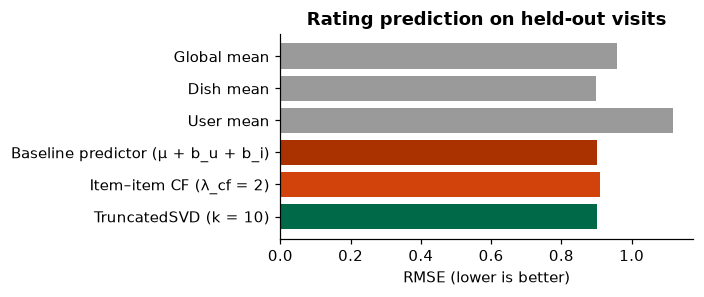

,method,test RMSE,test MAE
0,Global mean,0.959,0.813
1,Dish mean,0.897,0.727
2,User mean,1.119,0.891
3,Baseline predictor (μ + b_u + b_i),0.902,0.724
4,Item–item CF (λ_cf = 2),0.909,0.731
5,TruncatedSVD (k = 10),0.902,0.729


In [9]:
best_lam = float(sweep.loc[sweep["validation RMSE"].idxmin(), "λ_cf"])
best_k = int(svd_sweep.loc[svd_sweep["validation RMSE"].idxmin(), "components"])
model_full_train = R.train(menu, train_full)
test_scores = R.rmse_mae(model_full_train, train_full, test)
mat_f, users_f = R.rating_matrix(train_full, slugs); base_f = R.baseline(mat_f); res_f = R.residuals(mat_f, base_f)
uf = {u: k for k, u in enumerate(users_f)}
cf_err = [R.predict_rating(model_full_train.taste_raw, res_f, base_f, uf.get(u, -1), slugs.index(s), best_lam) - r
          for u, s, r in test[["user_id", "item_slug", "rating"]].itertuples(index=False)]
rows = [
    ("Global mean", test_scores["rmse_global_mean"], test_scores["mae_global_mean"]),
    ("Dish mean", test_scores["rmse_item_mean"], test_scores["mae_item_mean"]),
    ("User mean", test_scores["rmse_user_mean"], test_scores["mae_user_mean"]),
    ("Baseline predictor (μ + b_u + b_i)", test_scores["rmse_baseline"], test_scores["mae_baseline"]),
    (f"Item–item CF (λ_cf = {best_lam:g})", float(np.sqrt(np.mean(np.square(cf_err)))), float(np.mean(np.abs(cf_err)))),
    (f"TruncatedSVD (k = {best_k})", *svd_rmse(train_full, test, best_k)),
]
rating_table = pd.DataFrame(rows, columns=["method", "test RMSE", "test MAE"])
plt.figure(figsize=(6.5, 2.8))
plt.barh(rating_table["method"], rating_table["test RMSE"], color=[GREY]*3 + [BROWN, ORANGE, GREEN])
plt.gca().invert_yaxis(); plt.xlabel("RMSE (lower is better)"); plt.title("Rating prediction on held-out visits")
save("04_rating_prediction")
rating_table.round(3)

**Reading the result.** The baseline predictor (who rates high or low, and which dishes are liked overall) does most of the work. With about 6 ratings per demo user, there are too few overlapping raters for CF or SVD to add much on top: their correction is damped towards zero on validation. This is the classic **sparsity / cold-start** problem.

That is why the website does **not** depend on rating prediction. "You may also like" combines taste similarity with content similarity, which needs no ratings at all.

## 5. Visit association rules ("eaten together")

- From held-in visits, using only dishes rated ≥ 3 (eaten and enjoyed).
- `confidence = n_ij / (n_i + 5)` (shrunk), `lift = n_ij·V / (n_i·n_j)`.
- Rules with fewer than 3 visits or lift ≤ 1 are dropped.

In [10]:
st = R.cooccurrence(train_full, slugs)
rules = []
for i in range(len(slugs)):
    for j in range(len(slugs)):
        if st.confidence[i, j] > 0:
            rules.append((NAME[slugs[i]], NAME[slugs[j]], int(st.n_ij[i, j]), st.n_ij[i, j] / st.visits,
                          st.n_ij[i, j] / st.n_i[i], st.lift[i, j]))
rules = pd.DataFrame(rules, columns=["if guests enjoy", "they also enjoy", "visits", "support", "confidence", "lift"])
print(f"{len(rules)} rules from {st.visits} visits; showing rules seen in at least 5 visits")
rules[rules.visits >= 5].sort_values(["lift", "visits"], ascending=False).head(15).round(3)

138 rules from 1012 visits; showing rules seen in at least 5 visits


,if guests enjoy,they also enjoy,visits,support,confidence,lift
11,Cheese Garlic Bread,Paneer Barbeque Pizza,6,0.006,0.167,21.083
87,Paneer Barbeque Pizza,Cheese Garlic Bread,6,0.006,0.750,21.083
86,Nachos with Cheese Dip,Strawberry Shake,8,0.008,0.216,9.946
128,Strawberry Shake,Nachos with Cheese Dip,8,0.008,0.364,9.946
95,Peri Peri French Fries,Spicy Salsa Barbeque Burger,6,0.006,0.140,9.414
124,Spicy Salsa Barbeque Burger,Peri Peri French Fries,6,0.006,0.400,9.414
109,Royal Paneer Grilled Burger,Sizzling Italian Fries,5,0.005,0.263,8.070
119,Sizzling Italian Fries,Royal Paneer Grilled Burger,5,0.005,0.152,8.070
2,Alfredo (White Sauce),Cheese Garlic Bread,5,0.005,0.278,7.809
7,Cheese Garlic Bread,Alfredo (White Sauce),5,0.005,0.139,7.809


## 6. Quality score

A dish with three 5★ ratings should not outrank one with eighty 4★ ratings. The **Bayesian average** `(m·μ + Σr) / (m + n)` (m = 10) pulls small samples towards the overall mean.

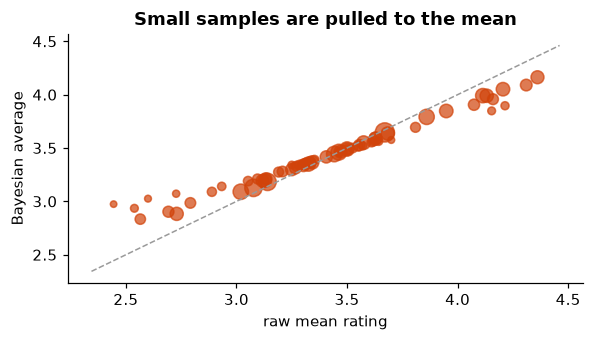

In [11]:
agg = train_full.groupby("item_slug").rating.agg(["mean", "count"])
bayes = pd.Series(R.bayesian_average(train_full, slugs), index=slugs)
plt.figure(figsize=(5.5, 3.2))
plt.scatter(agg["mean"], bayes[agg.index], s=agg["count"] * 2, color=ORANGE, alpha=0.7)
lims = [agg["mean"].min() - 0.1, agg["mean"].max() + 0.1]
plt.plot(lims, lims, color=GREY, lw=1, ls="--")
plt.xlabel("raw mean rating"); plt.ylabel("Bayesian average"); plt.title("Small samples are pulled to the mean")
save("05_bayesian_quality")

## 7. Hybrid weights (grid search on validation)

- Each list's three weights move in steps of 0.1 and sum to 1 (66 combinations per list), evaluated on the validation split.
- **Popularity bias.** HitRate alone rewards recommending the same popular dishes to everyone: popular dishes are the ones most often liked. A list that is the same for every dish is not useful.
- So the objective is **HitRate@5 × coverage@5**: accuracy and catalogue variety count equally. Coverage is the share of dishes that appear in some dish's top 5. Ties go to the combination closest to the design defaults.
- *History:* R2 first used "best HitRate with coverage ≥ 60 %". After the flag-parsing fix in R3, that rule picked a 60 %-popularity list sitting exactly on the 60 % line, so the objective was changed on validation results (ADR-074).

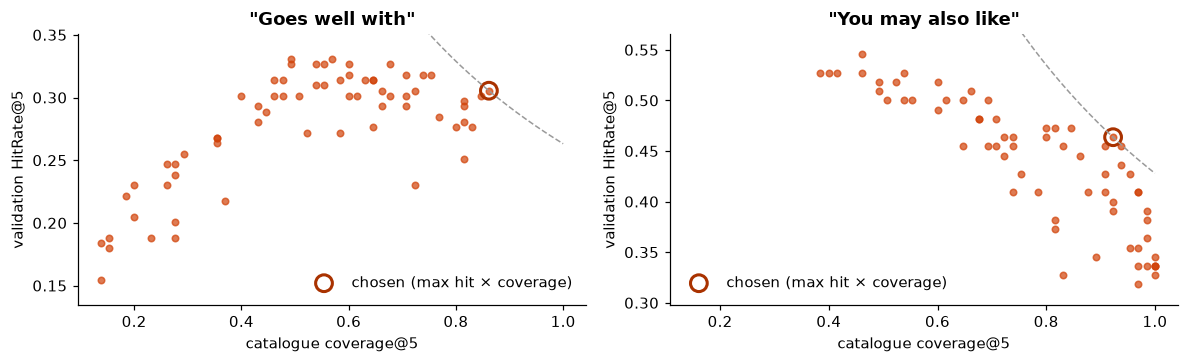

,co-occurrence,quality,content,hit,coverage,hit × coverage,distance
0,500,0,500,0.305,0.862,0.263,700
1,400,0,600,0.301,0.846,0.255,900
2,800,0,200,0.297,0.815,0.242,500
3,500,100,400,0.318,0.754,0.240,500
4,300,0,700,0.293,0.815,0.239,1100


,content,taste,quality,hit,coverage,hit × coverage,distance
0,500,200,300,0.464,0.923,0.428,200
1,600,200,200,0.455,0.938,0.427,200
2,600,100,300,0.455,0.908,0.413,400
3,500,300,200,0.436,0.938,0.410,0
4,700,100,200,0.427,0.954,0.408,400


On HitRate alone, SIMILAR would pick content/taste/quality = 100/100/800 (HitRate 0.545, coverage 46%): mostly the same popular dishes for everyone.


In [12]:
def grid():
    for a in range(0, 1001, 100):
        for b in range(0, 1001 - a, 100):
            yield a, b, 1000 - a - b
def list_coverage(m, kind):
    return len({e for s in m.slugs for e in R.top(m, s, kind, 5)}) / len(m.slugs)
comp_rows, sim_rows = [], []
for a, b, c in grid():
    m = R.with_weights(model_in, dict(R.DEFAULT_WEIGHTS, compCoocPm=a, compQualityPm=b, compContentPm=c))
    comp_rows.append((a, b, c, R.eval_complement(lambda s: R.top(m, s, "COMPLEMENT", 10), valid)["hit_rate"],
                      list_coverage(m, "COMPLEMENT")))
    m = R.with_weights(model_in, dict(R.DEFAULT_WEIGHTS, simContentPm=a, simTastePm=b, simQualityPm=c))
    sim_rows.append((a, b, c, R.eval_similar(lambda s: R.top(m, s, "SIMILAR", 10), train_in, valid, ROLE)["hit_rate"],
                     list_coverage(m, "SIMILAR")))
def choose(rows, default):
    df = pd.DataFrame(rows, columns=["w1", "w2", "w3", "hit", "coverage"])
    df["hit × coverage"] = df.hit * df.coverage
    df["distance"] = (df[["w1", "w2", "w3"]] - np.array(default)).abs().sum(axis=1)
    return df.sort_values(["hit × coverage", "distance"], ascending=[False, True]).reset_index(drop=True)
comp_grid = choose(comp_rows, (600, 250, 150)).rename(columns={"w1": "co-occurrence", "w2": "quality", "w3": "content"})
sim_grid = choose(sim_rows, (500, 300, 200)).rename(columns={"w1": "content", "w2": "taste", "w3": "quality"})
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
for a, g, title, chosen_w in ((ax[0], comp_grid, '"Goes well with"', "co-occurrence"), (ax[1], sim_grid, '"You may also like"', "content")):
    a.scatter(g.coverage, g.hit, s=18, color=ORANGE, alpha=0.7)
    a.scatter([g.coverage[0]], [g.hit[0]], s=120, facecolors="none", edgecolors=BROWN, linewidths=2, label="chosen (max hit × coverage)")
    xs = np.linspace(0.15, 1.0, 50)
    a.plot(xs, g["hit × coverage"][0] / xs, color=GREY, ls="--", lw=1)
    a.set_ylim(g.hit.min() - 0.02, g.hit.max() + 0.02)
    a.set_xlabel("catalogue coverage@5"); a.set_ylabel("validation HitRate@5"); a.set_title(title); a.legend(frameon=False)
save("07_weight_search")
display(comp_grid.head(5).round(3)); display(sim_grid.head(5).round(3))
best_unconstrained = sim_grid.sort_values("hit", ascending=False).iloc[0]
print(f"On HitRate alone, SIMILAR would pick content/taste/quality = "
      f"{int(best_unconstrained.content)}/{int(best_unconstrained.taste)}/{int(best_unconstrained.quality)} "
      f"(HitRate {best_unconstrained.hit:.3f}, coverage {best_unconstrained.coverage:.0%}): mostly the same popular dishes for everyone.")

In [13]:
best_c, best_s = comp_grid.iloc[0], sim_grid.iloc[0]
CHOSEN = {"compCoocPm": int(best_c["co-occurrence"]), "compQualityPm": int(best_c["quality"]),
          "compContentPm": int(best_c["content"]), "simContentPm": int(best_s["content"]),
          "simTastePm": int(best_s["taste"]), "simQualityPm": int(best_s["quality"])}
# A list's weights must not be all zero (database CHECK); the objective never picks that (coverage would be ~0).
print("Chosen weights (per-mille):", CHOSEN)

Chosen weights (per-mille): {'compCoocPm': 500, 'compQualityPm': 0, 'compContentPm': 500, 'simContentPm': 500, 'simTastePm': 200, 'simQualityPm': 300}


## 8. Evaluation on the test split

- Everything is re-fitted on train + validation with the chosen weights and evaluated once on the held-out test visits.
- Each method is compared with simple baselines: random (seeded), popularity (quality score), content-only, and co-occurrence-only or CF-only.

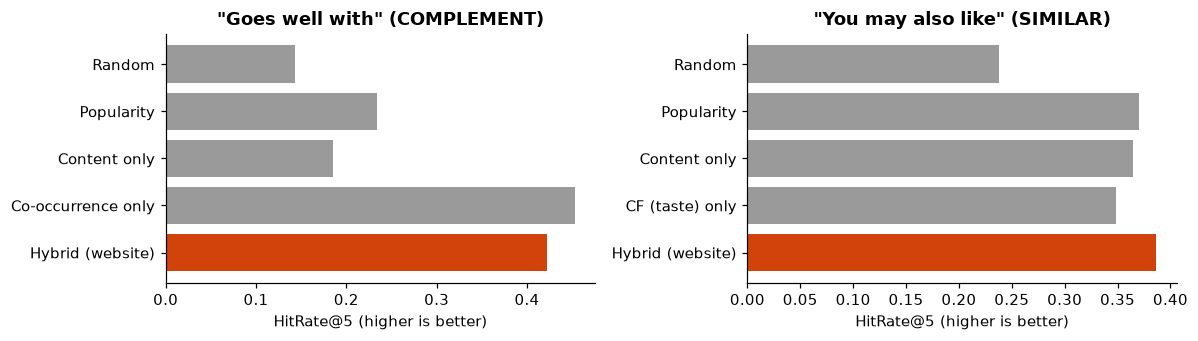

,method,queries,hit_rate,precision,recall
0,Random,265,0.143,0.029,0.113
1,Popularity,265,0.234,0.049,0.184
2,Content only,265,0.185,0.042,0.158
3,Co-occurrence only,265,0.453,0.098,0.386
4,Hybrid (website),265,0.423,0.091,0.369


,method,pairs,hit_rate
0,Random,181,0.238
1,Popularity,181,0.370
2,Content only,181,0.365
3,CF (taste) only,181,0.348
4,Hybrid (website),181,0.387


Coverage (dishes appearing in any top-5 list): 98.5%
Note: popularity scores well on HitRate because popular dishes are liked most often, but it shows the same dishes on every page (see §7). Standard error of a hit rate here: about ±0.03, so differences below about 0.06 are within noise.


In [14]:
final_eval = R.with_weights(R.train(menu, train_full), CHOSEN)
def ranked(model, kind, key):
    roles = ROLE
    def rec(slug):
        i = slugs.index(slug)
        cand = [j for j in range(len(slugs)) if j != i and ((roles[slugs[j]] != roles[slug]) == (kind == "COMPLEMENT"))]
        if key == "random":
            rng = np.random.default_rng(R.fnv1a32(slug))
            cand = list(rng.permutation(cand))
        else:
            score = {"popularity": lambda j: model.quality["ALL"][j], "content": lambda j: model.content[i, j],
                     "cooc": lambda j: (model.cooc[i, j], model.quality["ALL"][j]),
                     "taste": lambda j: (model.taste[i, j], model.quality["ALL"][j])}[key]
            cand = sorted(cand, key=lambda j: (score(j), slugs[j]) if not isinstance(score(j), tuple) else score(j), reverse=True)
        return [slugs[j] for j in cand]
    return rec
comp_methods = {"Random": ranked(final_eval, "COMPLEMENT", "random"),
                "Popularity": ranked(final_eval, "COMPLEMENT", "popularity"),
                "Content only": ranked(final_eval, "COMPLEMENT", "content"),
                "Co-occurrence only": ranked(final_eval, "COMPLEMENT", "cooc"),
                "Hybrid (website)": lambda s: R.top(final_eval, s, "COMPLEMENT", 10)}
sim_methods = {"Random": ranked(final_eval, "SIMILAR", "random"),
               "Popularity": ranked(final_eval, "SIMILAR", "popularity"),
               "Content only": ranked(final_eval, "SIMILAR", "content"),
               "CF (taste) only": ranked(final_eval, "SIMILAR", "taste"),
               "Hybrid (website)": lambda s: R.top(final_eval, s, "SIMILAR", 10)}
comp_table = pd.DataFrame([{"method": k, **R.eval_complement(f, test)} for k, f in comp_methods.items()])
sim_table = pd.DataFrame([{"method": k, **R.eval_similar(f, train_full, test, ROLE)} for k, f in sim_methods.items()])
fig, ax = plt.subplots(1, 2, figsize=(11, 3.2))
for a, t, title in ((ax[0], comp_table, '"Goes well with" (COMPLEMENT)'), (ax[1], sim_table, '"You may also like" (SIMILAR)')):
    colors = [ORANGE if m.startswith("Hybrid") else GREY for m in t.method]
    a.barh(t.method, t.hit_rate, color=colors); a.invert_yaxis(); a.set_xlabel("HitRate@5 (higher is better)"); a.set_title(title)
save("06_hit_rate")
display(comp_table.round(3)); display(sim_table.round(3))
print(f"Coverage (dishes appearing in any top-5 list): {R.coverage(final_eval):.1%}")
print("Note: popularity scores well on HitRate because popular dishes are liked most often, but it shows "
      "the same dishes on every page (see §7). Standard error of a hit rate here: about ±0.03, so "
      "differences below about 0.06 are within noise.")

## 9. What the website will show (examples)

Top 4 per list for a few dishes, from the final model (all data, chosen weights). Sold-out dishes are removed when the page is shown, and dishes the café links by hand come first.

In [15]:
final = R.with_weights(R.train(menu, fb), CHOSEN)
examples = ["korean-burger", "margherita", "peri-peri-pasta", "steam-momos", "premium-cold-coffee", "kulhad-maggi"]
pd.DataFrame([{"dish": NAME[s],
               "Goes well with": ", ".join(NAME[x] for x in R.top(final, s, "COMPLEMENT", 4)),
               "You may also like": ", ".join(NAME[x] for x in R.top(final, s, "SIMILAR", 4))} for s in examples])

,dish,Goes well with,You may also like
0,Korean Burger,"Korean Mojito, Korean Cheesy Fries, Peri Peri ...","Korean Pizza, Mexican King Burger, Kulhad Magg..."
1,Margherita,"Supreme Treat Garlic Bread, Korean Cheesy Frie...","Cheese Pull & Tear Garlic Bun, Pizza Di Sicili..."
2,Peri Peri Pasta,"Supreme Treat Garlic Bread, KitKat Chocolate S...","Alfredo (White Sauce), Cheese Pull & Tear Garl..."
3,Steam Momos,"Surprise Mojito, Kulhad Maggi, Cheese Pull & T...","Fried Momos, Peri Peri French Fries, Cheesy De..."
4,Premium Cold Coffee,"Korean Spicy Paneer, Cheese Pull & Tear Garlic...","Hot Coffee, Chocolate Cold Coffee, American Bl..."
5,Kulhad Maggi,"Hot Chocolate, Hot Coffee, Special Tea, Cheese...","Hot Passion Spicy Maggi, Mexican King Burger, ..."


## 10. Optional: sentiment of comments

A TF-IDF + logistic-regression classifier predicts positive / neutral / negative from the comment text. The demo comments come from templates, so this is an easy task; it is included to show the method, not as a strong result.

In [16]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score
strip = lambda df: [c.replace(n, " ") for c, n in zip(df.comment, df.item_slug.map(NAME))]  # remove dish names
vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2)
clf = LogisticRegression(max_iter=1000).fit(vec.fit_transform(strip(train_full)), train_full.sentiment)
pred = clf.predict(vec.transform(strip(test)))
print(f"Sentiment on test: accuracy {accuracy_score(test.sentiment, pred):.3f}, macro F1 {f1_score(test.sentiment, pred, average='macro'):.3f}")

Sentiment on test: accuracy 1.000, macro F1 1.000


## 11. Export (used by the app's tests in Phase R3)

In [17]:
path = R.export_reference(final, weights_pm=CHOSEN)
evaluation = {
    "description": "Phase R2 notebook results on DEMO data (test split = 20 % of visits by hash).",
    "chosen_weights_pm": CHOSEN,
    "rating_prediction": rating_table.round(4).to_dict("records"),
    "complement": comp_table.round(4).to_dict("records"),
    "similar": sim_table.round(4).to_dict("records"),
    "coverage": round(R.coverage(final_eval), 4),
    "best_cf_damping": best_lam, "best_svd_components": best_k,
}
(R.DATA / "evaluation.json").write_text(json.dumps(evaluation, indent=1, allow_nan=False) + "\n")
print("Wrote", path.relative_to(R.ROOT), "and data/reco/evaluation.json")

Wrote data/reco/reference_scores.json and data/reco/evaluation.json


## 12. Limitations

- **Synthetic data.** The ratings come from a generator with known rules, so the scores measure how well the methods recover those rules. Real feedback, for example an optional "which dish?" field on the feedback form (Q-25), would be needed to claim real-world accuracy.
- **Sparsity.** About 6 ratings per user leaves most user–dish pairs empty, so rating-based CF adds little over the baseline here.
- **No personalisation on the site.** The website has no accounts, so suggestions are per dish ("goes well with", "you may also like") or based on the guest's answers in "Help me choose". Nobody is tracked.
- **Fixed menu.** A dish added later has no ratings. It is still recommended through content similarity and quality until feedback exists (cold start).